# What Does an Image Representation Learn?

## TP1 — Exploring Tennis Action Images



### Problem

We want to classify the tennis action depicted in an image.

Before training a model, we must understand the dataset:
- Which action categories are available?
- How many images belong to each category?
- What visual information could distinguish these actions?
- Which examples are ambiguous?

### Your task

Download the dataset, inspect its organization, visualize examples,
and identify potential difficulties for image classification.

The input is a single RGB image.
The output is an action category.

This exercise concerns classification from still images:
we do not yet model how an action evolves over time.

# **1) Install dependencies**



In [1]:
%pip install -q kagglehub pandas matplotlib pillow

# **2) Download Dataset**

In [2]:
from pathlib import Path

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

dataset_dir = Path(
    kagglehub.dataset_download("orvile/tennis-player-actions-dataset")
)

print("Dataset downloaded to:", dataset_dir)

100%|██████████| 503M/503M [00:16<00:00, 32.2MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/orvile/tennis-player-actions-dataset/versions/1


**If authentication is requested, run this separately, then rerun previous Cell:**



In [3]:
kagglehub.login()

# **3) Inspect folders**

In [4]:
folders = sorted(
    p.relative_to(dataset_dir).as_posix()
    for p in dataset_dir.rglob("*")
    if p.is_dir()
)

print(dataset_dir)
print("Dataset folders:")
for folder in folders[:50]:
    print(folder)

if len(folders) > 50:
    print(f"... and {len(folders) - 50} more folders")

/root/.cache/kagglehub/datasets/orvile/tennis-player-actions-dataset/versions/1
Dataset folders:
Tennis Player Actions Dataset for Human Pose Estimation
Tennis Player Actions Dataset for Human Pose Estimation/annotations
Tennis Player Actions Dataset for Human Pose Estimation/images
Tennis Player Actions Dataset for Human Pose Estimation/images/backhand
Tennis Player Actions Dataset for Human Pose Estimation/images/forehand
Tennis Player Actions Dataset for Human Pose Estimation/images/ready_position
Tennis Player Actions Dataset for Human Pose Estimation/images/serve


# **4) Identify images and action labels**

In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_ALIASES = {
    "backhand": "backhand",
    "backhand_shot": "backhand",
    "forehand": "forehand",
    "forehand_shot": "forehand",
    "ready": "ready_position",
    "ready_position": "ready_position",
    "waiting_position": "ready_position",
    "serve": "serve",
    "serves": "serve",
    "service": "serve",
}

def infer_action(path):
    folders = path.relative_to(dataset_dir).parts[:-1]

    for folder in reversed(folders):
        name = folder.lower().strip().replace("-", "_").replace(" ", "_")
        if name in CLASS_ALIASES:
            return CLASS_ALIASES[name]

    return None

image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not image_paths:
    raise RuntimeError("No images found. Inspect the downloaded dataset.")

inventory = pd.DataFrame({
    "path": [str(p) for p in image_paths],
    "action": [infer_action(p) for p in image_paths],
})

unknown = inventory[inventory["action"].isna()]

if not unknown.empty:
    print(f"Images with unrecognized folder labels: {len(unknown)}")
    display(unknown.head())
    print("Check the folders and update CLASS_ALIASES if necessary.")

df = inventory.dropna(subset=["action"]).reset_index(drop=True)

if df.empty:
    raise RuntimeError("No classes recognized. Check the folder names.")

print(f"\nRecognized images: {len(df)}")
print(f"Recognized classes: {df['action'].nunique()}")
display(df.head())


Recognized images: 2000
Recognized classes: 4


,path,action
0,/root/.cache/kagglehub/datasets/orvile/tennis-...,backhand
1,/root/.cache/kagglehub/datasets/orvile/tennis-...,backhand
2,/root/.cache/kagglehub/datasets/orvile/tennis-...,backhand
3,/root/.cache/kagglehub/datasets/orvile/tennis-...,backhand
4,/root/.cache/kagglehub/datasets/orvile/tennis-...,backhand


# **5) Show the class distribution**

,images,percentage
action,,
backhand,500,25.0
forehand,500,25.0
ready_position,500,25.0
serve,500,25.0


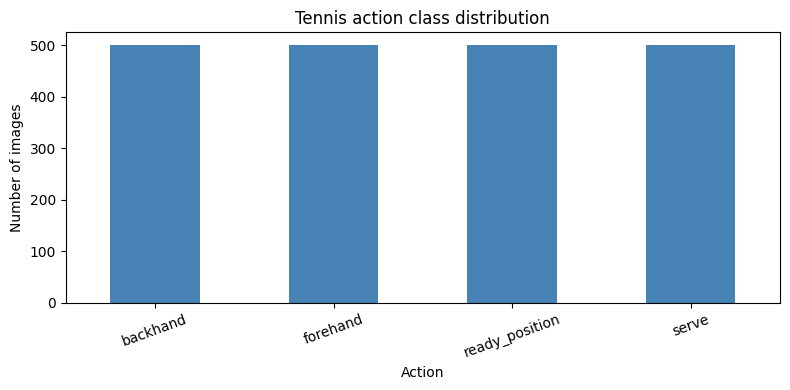

In [6]:
counts = df["action"].value_counts().sort_index()

summary = counts.rename("images").to_frame()
summary["percentage"] = (100 * counts / len(df)).round(1)
display(summary)

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.bar(ax=ax, color="steelblue")

ax.set(
    title="Tennis action class distribution",
    xlabel="Action",
    ylabel="Number of images",
)
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### **Question**
What does this plot show about the number of images in each action class? Why is it important to inspect this distribution before training and evaluating a classifier?

--- Write your answer here. ----

# **6) Visualize images from each class**

In [7]:
classes = sorted(df["action"].unique())
examples_per_class = 4

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=examples_per_class,
    figsize=(16, 3.5 * len(classes)),
    squeeze=False,
)

for row, action in enumerate(classes):
    class_images = df[df["action"] == action]
    samples = class_images.sample(
        n=min(examples_per_class, len(class_images)),
        random_state=42,
    )

    for ax in axes[row]:
        ax.axis("off")

    for column, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row, column]

        try:
            with Image.open(sample["path"]) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                ax.imshow(image)

            ax.set_title(f"{action}\n{Path(sample['path']).name}", fontsize=9)

        except (OSError, ValueError):
            ax.set_title("Unable to read this image")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# **Part 1 — Representations from a Random Encoder**

### What is an image representation?

An image contains pixel values. An encoder transforms these values into
a feature vector, also called a representation or embedding:

$$
z = f_\theta(x)
$$

- $x$: the input image.
- $f_\theta$: the encoder, parameterized by its weights \(\theta\).
- $z$: a vector representing the image.

A classifier could subsequently use this vector to predict an action:

$$
\hat{y} = g_\phi(z)
$$

The representation is therefore different from the final prediction:
it contains features that a downstream model can use.

### Our experiment

We will use a ResNet-18 encoder with randomly initialized weights.
It has not been trained to recognize tennis actions.

Nevertheless, its architecture still transforms images into feature
vectors. We will investigate whether their similarities reflect action
categories or other properties, such as colours and backgrounds.

**Prediction before running the code:**
Do you expect images of the same action to have similar representations?
Explain your reasoning.

Reference:
Bengio et al. (2013), Representation Learning:
https://doi.org/10.1109/TPAMI.2013.50

**Code: install dependencies**

In [8]:
%pip install -q timm scikit-learn tqdm

# **7) Create the random encoder**

In timm, num_classes=0 removes the classification head and returns pooled features.

In [9]:
import numpy as np
import torch
import timm

from torch.utils.data import Dataset, DataLoader
from timm.data import resolve_model_data_config, create_transform
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

random_encoder = timm.create_model(
    "resnet18",
    pretrained=False,     # Random weights: no pretrained weights loaded
    num_classes=0,        # Remove the classification head
    global_pool="avg",    # One feature vector per image
).to(device)

random_encoder.eval()

print("Feature-vector dimension:", random_encoder.num_features)

Device: cuda
Feature-vector dimension: 512


# **8) Prepare images**

Use deterministic preprocessing. Labels are retained for visualization but never passed to the encoder.

In [10]:
data_config = resolve_model_data_config(random_encoder)

image_transform = create_transform(
    **data_config,
    is_training=False,
)

print(image_transform)

class TennisImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image = self.transform(image)

        return image

# Keep every image and preserve its order.
feature_df = df.reset_index(drop=True).copy()

dataset = TennisImageDataset(feature_df, image_transform)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,       # Preserve alignment with feature_df
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


# **9) Extract representations**

In [11]:
feature_batches = []

with torch.inference_mode():
    for images in tqdm(loader, desc="Extracting random-encoder features"):
        images = images.to(device)
        features = random_encoder(images)
        feature_batches.append(features.cpu().numpy())

random_features = np.concatenate(feature_batches, axis=0)

assert len(random_features) == len(feature_df)
assert np.isfinite(random_features).all()

print("Feature matrix shape:", random_features.shape)
print("Each row represents one image.")
print("Each column represents one feature coordinate.")

Extracting random-encoder features:   0%|          | 0/63 [00:00<?, ?it/s]

Feature matrix shape: (2000, 512)
Each row represents one image.
Each column represents one feature coordinate.


# **10) How can we visualize the feature space?**

### From hundreds of dimensions to two

ResNet-18 produces a 512-dimensional vector for each image.
We cannot display all these dimensions directly.

We use Principal Component Analysis (PCA) to obtain a two-dimensional
projection. Its axes capture directions of variation in the features.

We first normalize each vector to unit length. This focuses the
exploration on feature direction rather than vector magnitude.

Important:
- Each point represents an image.
- Colours indicate action labels; PCA does not use those labels.
- Nearby points have similar projected representations.
- A two-dimensional projection loses information.
- Visible clusters do not establish classification performance.


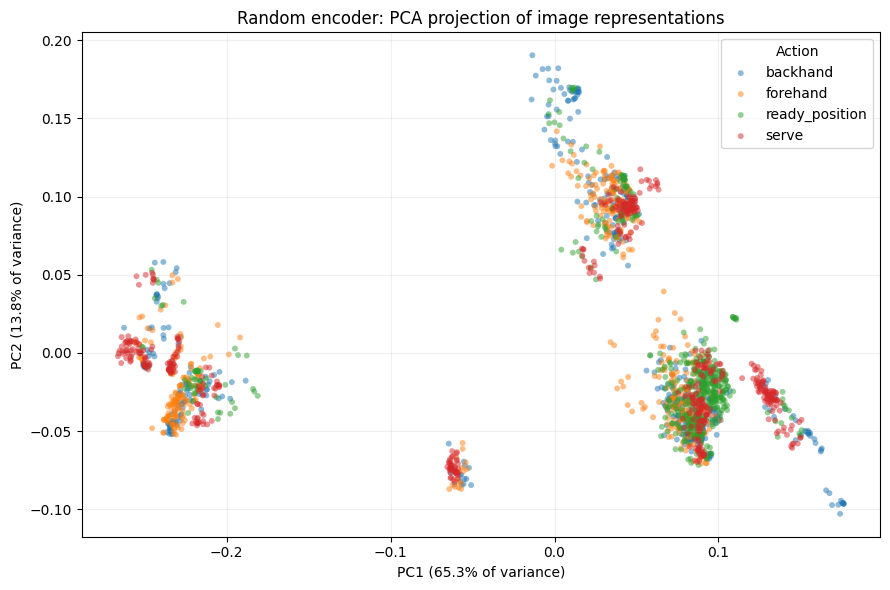

Variance captured by both axes: 79.1%


In [12]:
normalized_features = normalize(random_features, norm="l2")

pca = PCA(
    n_components=2,
    svd_solver="full",
)
coordinates = pca.fit_transform(normalized_features)

projection_df = feature_df.copy()
projection_df["PC1"] = coordinates[:, 0]
projection_df["PC2"] = coordinates[:, 1]

classes = sorted(projection_df["action"].unique())
cmap = plt.get_cmap("tab10")
class_colors = {action: cmap(i % 10) for i, action in enumerate(classes)}

variance = 100 * pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))

for action in classes:
    subset = projection_df[projection_df["action"] == action]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=action,
        color=class_colors[action],
        s=18,
        alpha=0.5,
        edgecolors="none",
    )

ax.set(
    title="Random encoder: PCA projection of image representations",
    xlabel=f"PC1 ({variance[0]:.1f}% of variance)",
    ylabel=f"PC2 ({variance[1]:.1f}% of variance)",
)
ax.legend(title="Action")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Variance captured by both axes: {variance.sum():.1f}%")

# **11) Compare class distributions**

Use the same bins for all classes and density normalization so larger classes do not automatically produce taller distributions.

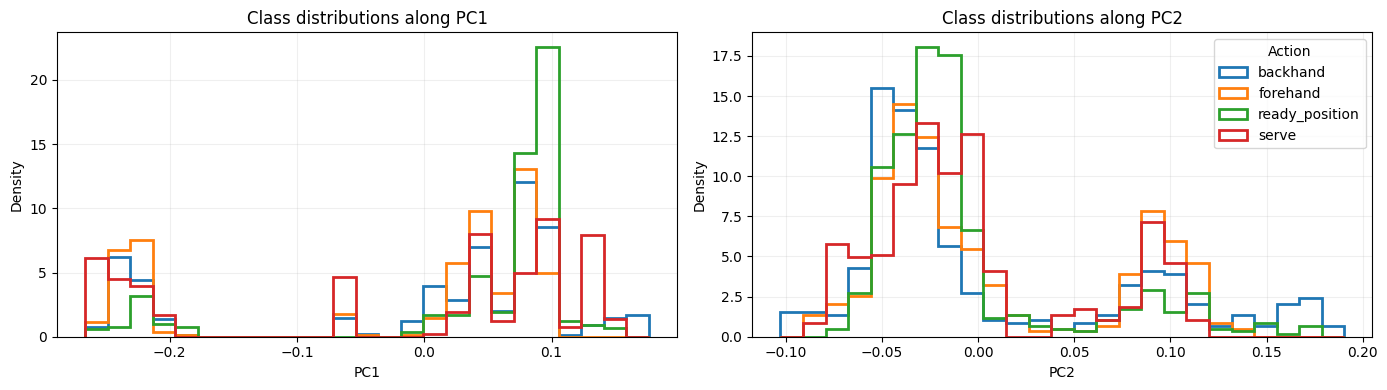

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, component in zip(axes, ["PC1", "PC2"]):
    bins = np.histogram_bin_edges(
        projection_df[component].to_numpy(),
        bins=25,
    )

    for action in classes:
        values = projection_df.loc[
            projection_df["action"] == action, component
        ]

        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=class_colors[action],
            label=action,
        )

    ax.set(
        title=f"Class distributions along {component}",
        xlabel=component,
        ylabel="Density",
    )
    ax.grid(alpha=0.2)

axes[1].legend(title="Action")
plt.tight_layout()
plt.show()

# **12) Inspect nearest neighbours**

This uses all 512 feature coordinates, not the PCA projection. The query image is excluded from its own neighbours.

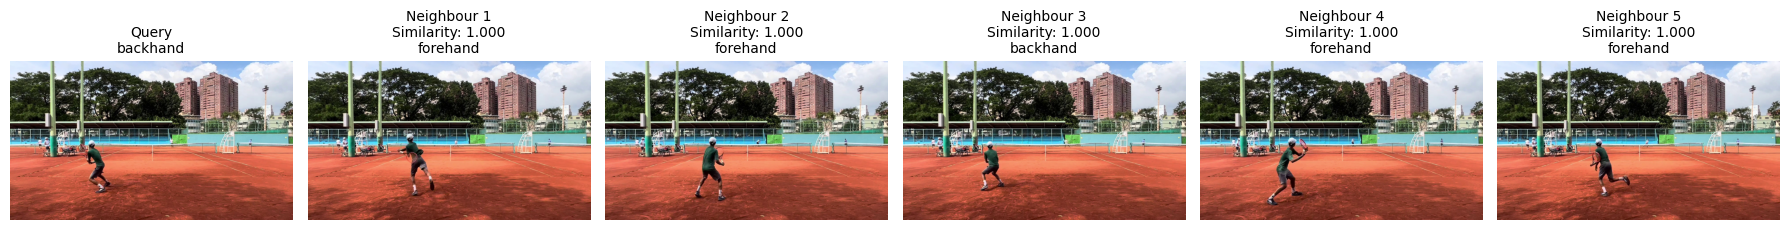

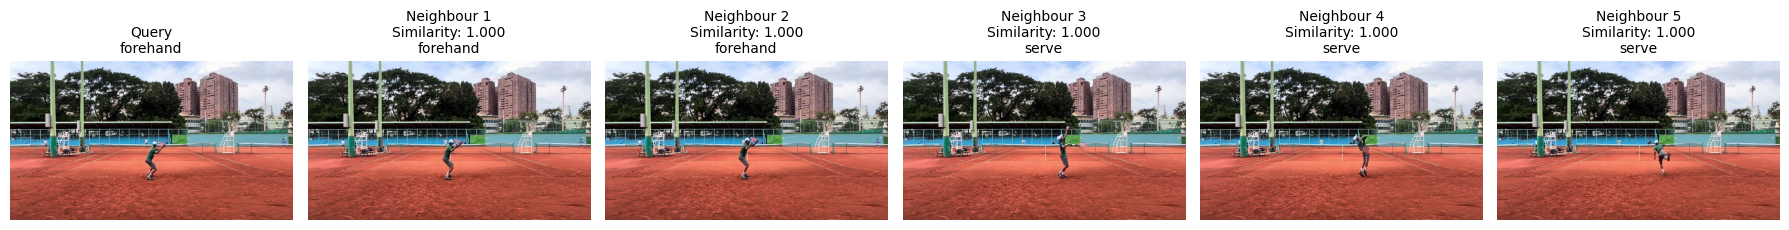

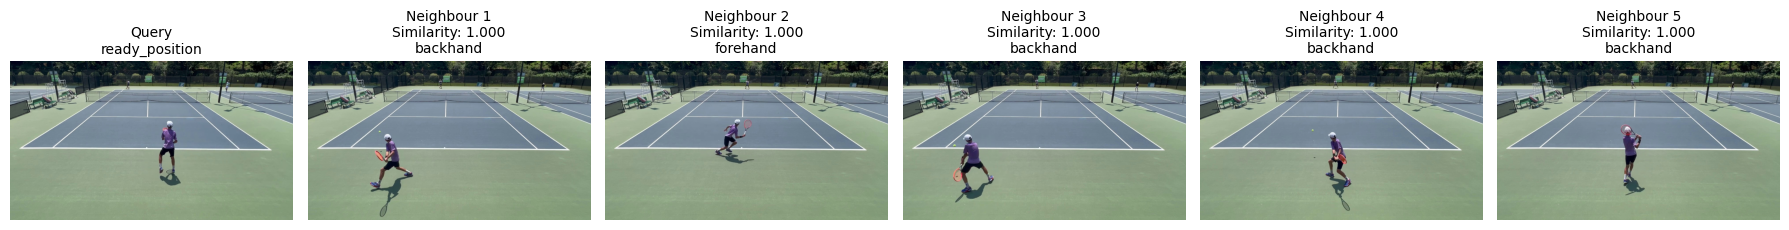

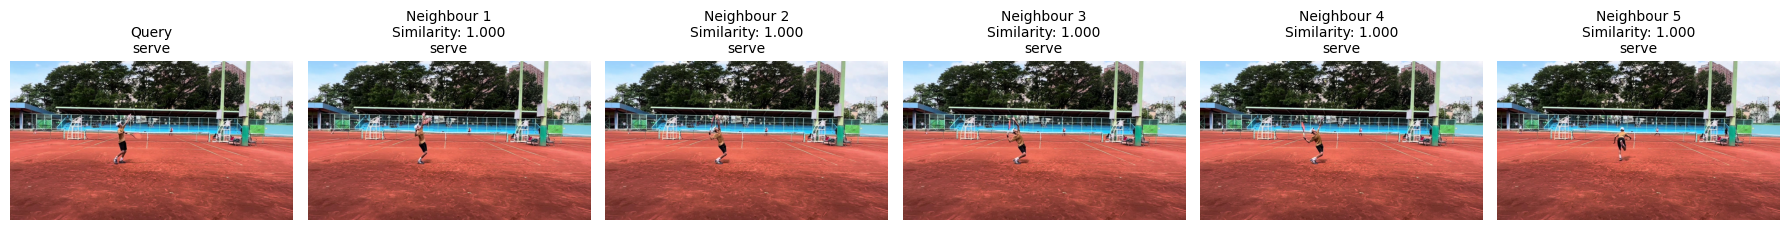

In [14]:
def show_neighbours(query_index, k=5):
    if not 0 <= query_index < len(feature_df):
        raise IndexError("query_index is outside the dataset.")

    k = min(k, len(feature_df) - 1)

    # Cosine similarity between unit-normalized feature vectors.
    similarities = normalized_features @ normalized_features[query_index]
    similarities[query_index] = -np.inf

    neighbour_indices = np.argsort(-similarities)[:k]
    indices = [query_index] + neighbour_indices.tolist()

    fig, axes = plt.subplots(
        1, len(indices), figsize=(3 * len(indices), 3.5), squeeze=False
    )

    for position, index in enumerate(indices):
        row = feature_df.iloc[index]
        ax = axes[0, position]

        with Image.open(row["path"]) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))

        heading = (
            "Query"
            if position == 0
            else f"Neighbour {position}\nSimilarity: {similarities[index]:.3f}"
        )
        ax.set_title(f"{heading}\n{row['action']}", fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Inspect one reproducibly selected query per action.
for action in classes:
    query_index = feature_df[
        feature_df["action"] == action
    ].sample(n=1, random_state=SEED).index[0]

    show_neighbours(query_index)

## Interpret your results

1. What is the shape of the feature matrix, and what do its axes represent?
2. Do the action classes overlap in the PCA plot?
3. How much variance does the two-dimensional projection retain?
4. What do the class-distribution plots add to the scatter plot?
5. Do nearest neighbours share an action, a background, colours,
   or a camera viewpoint? Give two examples.
6. Why might an untrained encoder produce visually similar neighbours?
7. Why can these plots alone not establish action-classification performance?

### Before the next experiment

Predict what will change when we replace the random weights with
pretrained weights while keeping the architecture, images, and
preprocessing unchanged.

## **Part 2 — Representations from an ImageNet-Pretrained Encoder**

Previously, we extracted representations from a randomly initialized
ResNet-18.

We now use the same architecture with weights learned through supervised
classification on ImageNet.

We remove its classification head and retain its encoder:

$$
z = f_{\theta_{\mathrm{ImageNet}}}(x)
$$

The encoder has learned from ImageNet images, but it has not been
fine-tuned on our tennis dataset.

### Objective

Investigate whether these pretrained representations organize tennis
images differently from random representations.

We will:
1. Extract one feature vector per image.
2. Visualize the vectors using PCA.
3. Compare action-class distributions.
4. Inspect nearest-neighbour images.

The tennis labels are used for visualization only.
They are not provided to the encoder.

### Predict before running

Will nearest neighbours share more information about body posture
and tennis actions? What evidence would support your prediction?

References:
- ResNet: https://doi.org/10.1109/CVPR.2016.90
- Representation learning: https://doi.org/10.1109/TPAMI.2013.50

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import timm

from pathlib import Path
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from timm.data import resolve_model_data_config, create_transform
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pretrained_encoder = timm.create_model(
    "resnet18.a1_in1k",
    pretrained=True,      # Download ImageNet-pretrained weights
    num_classes=0,        # Remove the classification head
    global_pool="avg",
).to(device)

pretrained_encoder.eval()

print("Device:", device)
print("Feature dimension:", pretrained_encoder.num_features)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
Feature dimension: 512


In [16]:
if "feature_df" not in globals():
    feature_df = df.reset_index(drop=True).copy()

assert {"path", "action"}.issubset(feature_df.columns)

pretrained_config = resolve_model_data_config(pretrained_encoder)

# Preserve the previous preprocessing for a controlled comparison.
if "image_transform" not in globals():
    image_transform = create_transform(
        **pretrained_config,
        is_training=False,
    )
else:
    print("Reusing preprocessing from the random-encoder experiment.")

print(image_transform)
print("Pretrained model's expected configuration:", pretrained_config)

pretrained_dataset = TennisImageDataset(feature_df, image_transform)

pretrained_loader = DataLoader(
    pretrained_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

Reusing preprocessing from the random-encoder experiment.
Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)
Pretrained model's expected configuration: {'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.95, 'crop_mode': 'center'}


In [17]:
feature_batches = []

with torch.inference_mode():
    for images in tqdm(
        pretrained_loader,
        desc="Extracting ImageNet-pretrained features",
    ):
        images = images.to(device)
        features = pretrained_encoder(images)
        feature_batches.append(features.cpu().numpy())

pretrained_features = np.concatenate(feature_batches, axis=0)

assert len(pretrained_features) == len(feature_df)
assert np.isfinite(pretrained_features).all()

print("Feature matrix:", pretrained_features.shape)

Extracting ImageNet-pretrained features:   0%|          | 0/63 [00:00<?, ?it/s]

Feature matrix: (2000, 512)


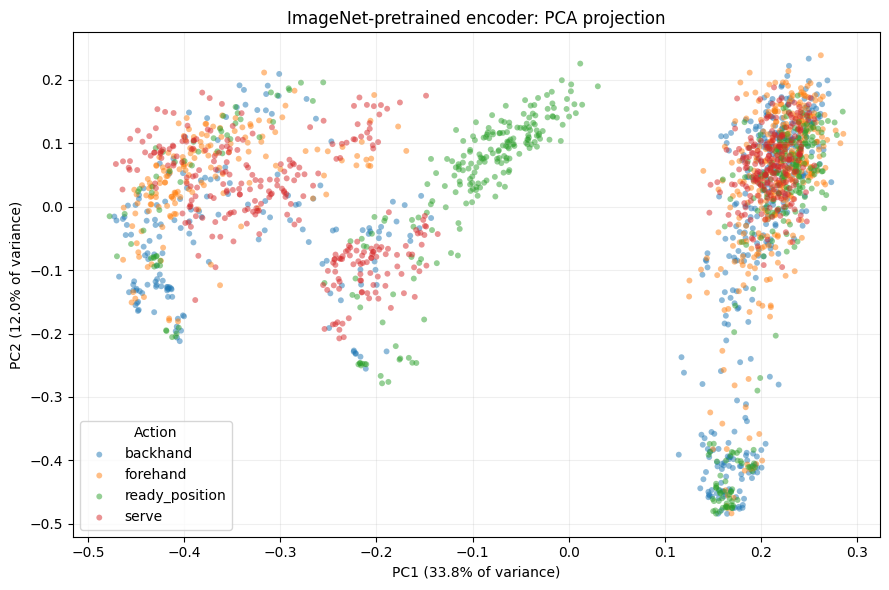

Variance retained: 45.8%


In [18]:
pretrained_normalized = normalize(pretrained_features, norm="l2")

pretrained_pca = PCA(n_components=2, svd_solver="full")
pretrained_coordinates = pretrained_pca.fit_transform(
    pretrained_normalized
)

pretrained_projection = feature_df.copy()
pretrained_projection["PC1"] = pretrained_coordinates[:, 0]
pretrained_projection["PC2"] = pretrained_coordinates[:, 1]

classes = sorted(feature_df["action"].unique())
cmap = plt.get_cmap("tab10")
class_colors = {
    action: cmap(i % 10) for i, action in enumerate(classes)
}

variance = 100 * pretrained_pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))

for action in classes:
    subset = pretrained_projection[
        pretrained_projection["action"] == action
    ]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        color=class_colors[action],
        label=action,
        s=18,
        alpha=0.5,
        edgecolors="none",
    )

ax.set(
    title="ImageNet-pretrained encoder: PCA projection",
    xlabel=f"PC1 ({variance[0]:.1f}% of variance)",
    ylabel=f"PC2 ({variance[1]:.1f}% of variance)",
)
ax.legend(title="Action")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Variance retained: {variance.sum():.1f}%")

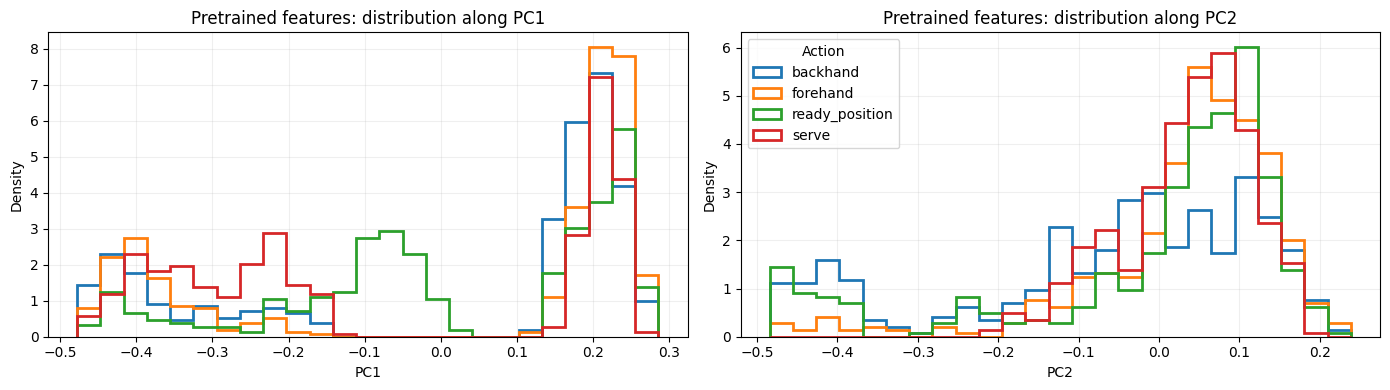

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, component in zip(axes, ["PC1", "PC2"]):
    bins = np.histogram_bin_edges(
        pretrained_projection[component],
        bins=25,
    )

    for action in classes:
        values = pretrained_projection.loc[
            pretrained_projection["action"] == action,
            component,
        ]

        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=class_colors[action],
            label=action,
        )

    ax.set(
        title=f"Pretrained features: distribution along {component}",
        xlabel=component,
        ylabel="Density",
    )
    ax.grid(alpha=0.2)

axes[1].legend(title="Action")
plt.tight_layout()
plt.show()

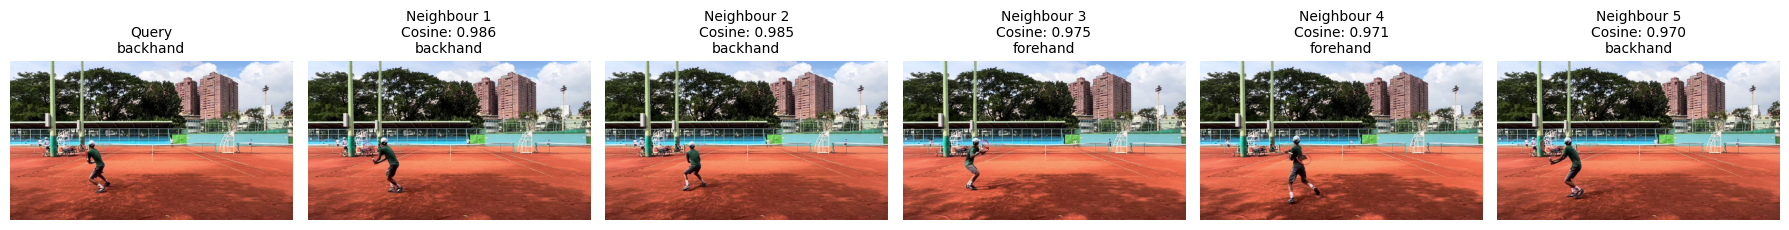

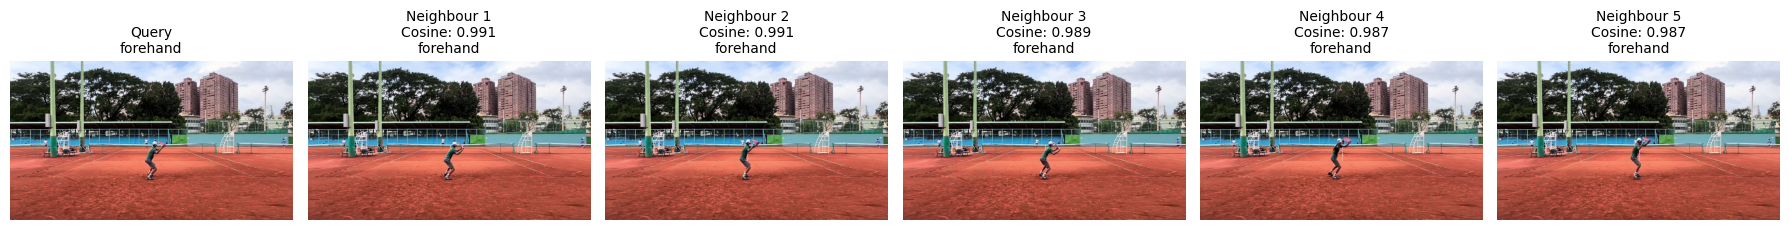

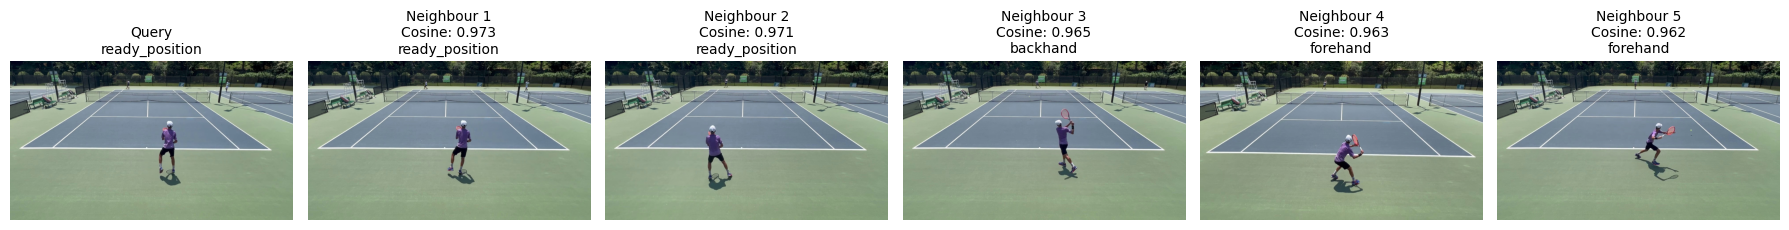

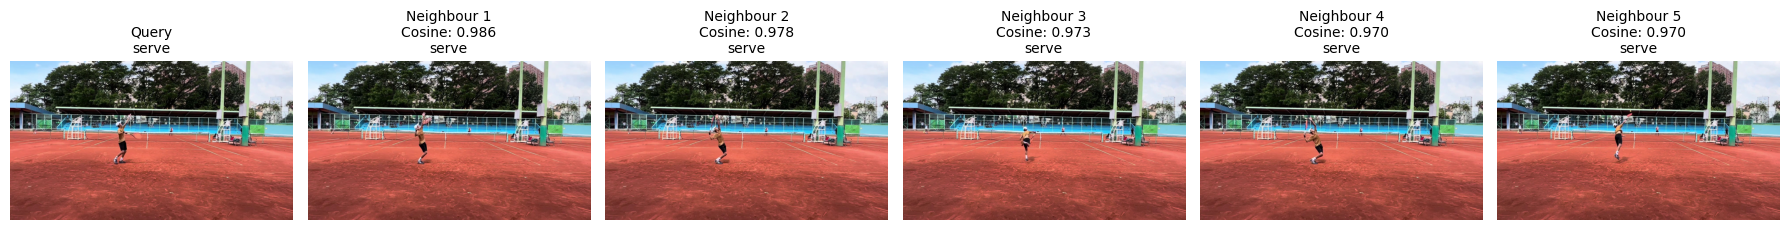

In [20]:
def show_pretrained_neighbours(query_index, k=5):
    if not 0 <= query_index < len(feature_df):
        raise IndexError("Invalid query index.")

    k = min(k, len(feature_df) - 1)

    similarities = (
        pretrained_normalized @ pretrained_normalized[query_index]
    )
    similarities[query_index] = -np.inf

    neighbours = np.argsort(-similarities)[:k]
    indices = [query_index] + neighbours.tolist()

    fig, axes = plt.subplots(
        1, len(indices),
        figsize=(3 * len(indices), 3.5),
        squeeze=False,
    )

    for position, index in enumerate(indices):
        row = feature_df.iloc[index]
        ax = axes[0, position]

        with Image.open(row["path"]) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))

        heading = (
            "Query"
            if position == 0
            else f"Neighbour {position}\nCosine: {similarities[index]:.3f}"
        )
        ax.set_title(f"{heading}\n{row['action']}", fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

for action in classes:
    query_index = feature_df[
        feature_df["action"] == action
    ].sample(n=1, random_state=SEED).index[0]

    show_pretrained_neighbours(query_index)

## Random versus pretrained representations

1. Compare nearest neighbours for the same query images.
   What changed? Give two concrete examples.

2. Do the pretrained features appear to organize images by action,
   background, or other visual characteristics?

3. Compare the class distributions and PCA projections.
   What observations support your interpretation?

4. Does a clearer-looking PCA plot prove better classification?
   Explain what additional experiment is needed.

5. Why might ImageNet pretraining help despite using a different dataset?

6. What information might still require learning from tennis images?

Important:
The random and pretrained PCA projections were fitted separately.
Their axes are different: do not compare point coordinates directly.

A higher percentage of explained variance does not mean that an encoder
is better at recognizing tennis actions.

## Part 3: Learning Representations by Predicting Image Rotations

We create training targets automatically by rotating each image:

| Label | Applied rotation |
|---|---|
| 0 | 0° |
| 1 | 90° |
| 2 | 180° |
| 3 | 270° |

The network predicts the applied rotation, without receiving tennis-action
labels during pretraining.

After training, we remove the rotation classifier and inspect the
representations of original, unrotated images.

### Hypothesis

Rotation prediction may encourage useful shape and posture features.
However, the network could instead exploit background orientation.

Successful rotation prediction does not necessarily imply useful
tennis-action representations.

Reference:
https://arxiv.org/abs/1803.07728


In [1], authors propose to predict the geometric transformation applied to the entire image

<center width="100%"><img src="https://miro.medium.com/v2/resize:fit:908/1*enAk96Zn6andqoBetBy5Jg.png" width="800px" style="padding-top: 10px; padding-bottom: 10px"></center>


[1] S. Gidaris et al. “Unsupervised Representation Learning by Predicting Image Rotations”. In: ICLR. 2018.

**Prepare a fixed split**



In [21]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import timm

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Row indices preserve alignment with previously extracted features.
all_indices = np.arange(len(feature_df))

train_indices, evaluation_indices = train_test_split(
    all_indices,
    test_size=0.20,
    stratify=feature_df["action"],
    random_state=SEED,
)

rotation_train_indices, rotation_val_indices = train_test_split(
    train_indices,
    test_size=0.20,
    stratify=feature_df.iloc[train_indices]["action"],
    random_state=SEED,
)

print("Rotation training images:", len(rotation_train_indices))
print("Rotation validation images:", len(rotation_val_indices))
print("Reserved evaluation images:", len(evaluation_indices))

Rotation training images: 1280
Rotation validation images: 320
Reserved evaluation images: 400


**Generate four rotations per image**

Reuse the previous deterministic image_transform. Rotating square tensors with torch.rot90 avoids interpolation artefacts.

In [22]:
class RotationDataset(Dataset):
    def __init__(self, frame, indices, transform):
        self.frame = frame.iloc[indices].reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        with Image.open(self.frame.iloc[index]["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image = self.transform(image)

        if image.shape[-2] != image.shape[-1]:
            raise ValueError("Rotation exercise requires square inputs.")

        rotated_images = torch.stack([
            torch.rot90(image, k=k, dims=(-2, -1))
            for k in range(4)
        ])

        rotation_labels = torch.arange(4, dtype=torch.long)

        return rotated_images, rotation_labels


rotation_train_dataset = RotationDataset(
    feature_df, rotation_train_indices, image_transform
)
rotation_val_dataset = RotationDataset(
    feature_df, rotation_val_indices, image_transform
)

# Each source image produces four examples:
# batch_size=16 becomes 64 rotated images.
rotation_train_loader = DataLoader(
    rotation_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

rotation_val_loader = DataLoader(
    rotation_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

**Visualize the generated targets**

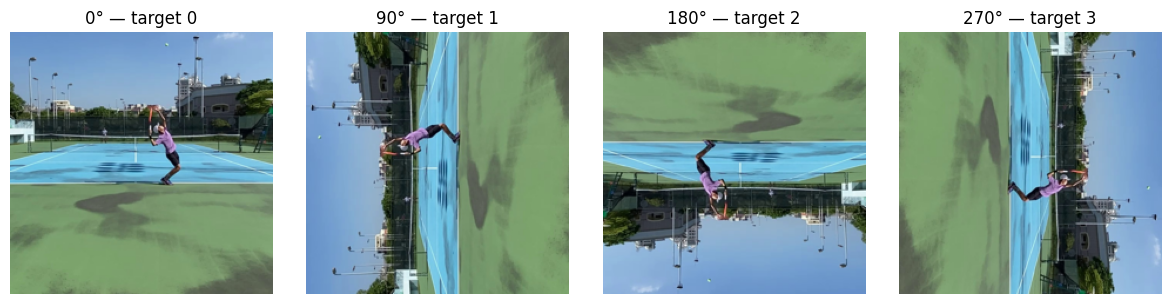

In [23]:
rotations, targets = rotation_train_dataset[0]

# Undo normalization for display.
config = resolve_model_data_config(random_encoder)
mean = torch.tensor(config["mean"]).view(3, 1, 1)
std = torch.tensor(config["std"]).view(3, 1, 1)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for k, ax in enumerate(axes):
    image = (rotations[k] * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(f"{90 * k}° — target {targets[k].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Create the rotation classifier**

In [24]:
torch.manual_seed(SEED)

rotation_model = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=4,
    global_pool="avg",
).to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    rotation_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

EPOCHS = 10  # Initial teaching run; inspect convergence before extending.

**Train and validate**

Select the checkpoint using rotation validation loss, without consulting the reserved evaluation images.

In [25]:
def run_rotation_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.set_grad_enabled(training):
        for images, targets in loader:
            # [B, 4, C, H, W] -> [4B, C, H, W]
            images = images.flatten(0, 1).to(device)
            targets = targets.flatten().to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, targets)

            if training:
                loss.backward()
                optimizer.step()

            n = targets.size(0)
            total_loss += loss.item() * n
            total_correct += (logits.argmax(1) == targets).sum().item()
            total_examples += n

    return (
        total_loss / total_examples,
        total_correct / total_examples,
    )


history = []
best_val_loss = float("inf")
best_state = None

for epoch in tqdm(range(1, EPOCHS + 1), desc="Rotation pretraining"):
    train_loss, train_acc = run_rotation_epoch(
        rotation_model, rotation_train_loader, optimizer
    )
    val_loss, val_acc = run_rotation_epoch(
        rotation_model, rotation_val_loader
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in rotation_model.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}: "
        f"train loss={train_loss:.3f}, accuracy={train_acc:.3f} | "
        f"val loss={val_loss:.3f}, accuracy={val_acc:.3f}"
    )

rotation_model.load_state_dict(best_state)
rotation_model.eval()

Rotation pretraining:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01: train loss=0.863, accuracy=0.856 | val loss=0.363, accuracy=0.991
Epoch 02: train loss=0.164, accuracy=0.999 | val loss=0.053, accuracy=1.000
Epoch 03: train loss=0.028, accuracy=1.000 | val loss=0.015, accuracy=1.000
Epoch 04: train loss=0.010, accuracy=1.000 | val loss=0.007, accuracy=1.000
Epoch 05: train loss=0.005, accuracy=1.000 | val loss=0.004, accuracy=1.000
Epoch 06: train loss=0.003, accuracy=1.000 | val loss=0.003, accuracy=1.000
Epoch 07: train loss=0.002, accuracy=1.000 | val loss=0.002, accuracy=1.000
Epoch 08: train loss=0.002, accuracy=1.000 | val loss=0.001, accuracy=1.000
Epoch 09: train loss=0.001, accuracy=1.000 | val loss=0.001, accuracy=1.000
Epoch 10: train loss=0.001, accuracy=1.000 | val loss=0.001, accuracy=1.000


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (drop_block): Identity()
      (act1): ReLU(inplace=True)
      (aa): Identity()
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act2): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, m

**Inspect learning curves**

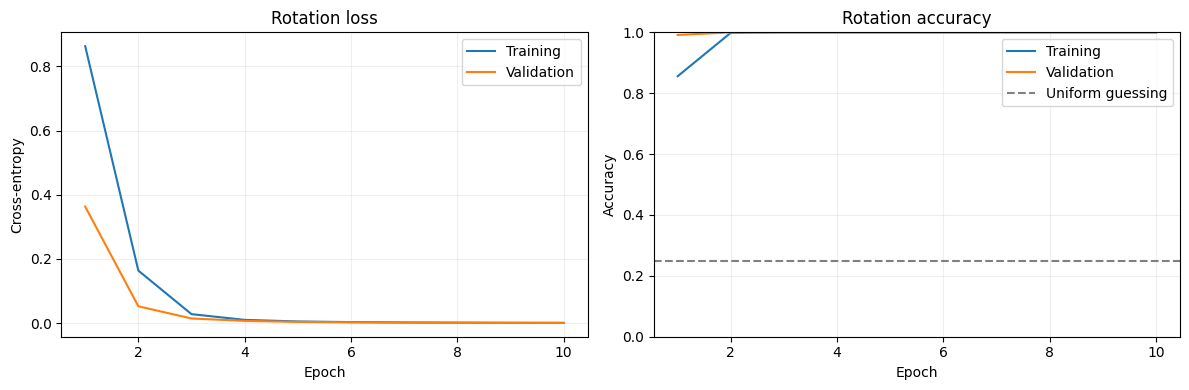

In [26]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Training")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set(title="Rotation loss", xlabel="Epoch", ylabel="Cross-entropy")

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"], label="Training"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"], label="Validation"
)
axes[1].axhline(
    0.25, color="grey", linestyle="--", label="Uniform guessing"
)
axes[1].set(
    title="Rotation accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1)
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Extract representations from unrotated images**

Keep the rotation classifier intact and make a separate encoder copy.

In [27]:
rotation_encoder = copy.deepcopy(rotation_model)
rotation_encoder.reset_classifier(0, global_pool="avg")
rotation_encoder.eval()

class OriginalImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        with Image.open(self.frame.iloc[index]["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            return self.transform(image)


original_loader = DataLoader(
    OriginalImageDataset(feature_df, image_transform),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

feature_batches = []

with torch.inference_mode():
    for images in tqdm(original_loader, desc="Extracting rotation features"):
        features = rotation_encoder(images.to(device))
        feature_batches.append(features.cpu().numpy())

rotation_features = np.concatenate(feature_batches)

assert rotation_features.shape == (len(feature_df), 512)
assert np.isfinite(rotation_features).all()

print("Rotation-trained feature matrix:", rotation_features.shape)

Extracting rotation features:   0%|          | 0/63 [00:00<?, ?it/s]

Rotation-trained feature matrix: (2000, 512)


**Compare all three encoders on reserved images**

This assumes the earlier cells produced random_features and pretrained_features in the same feature_df order.

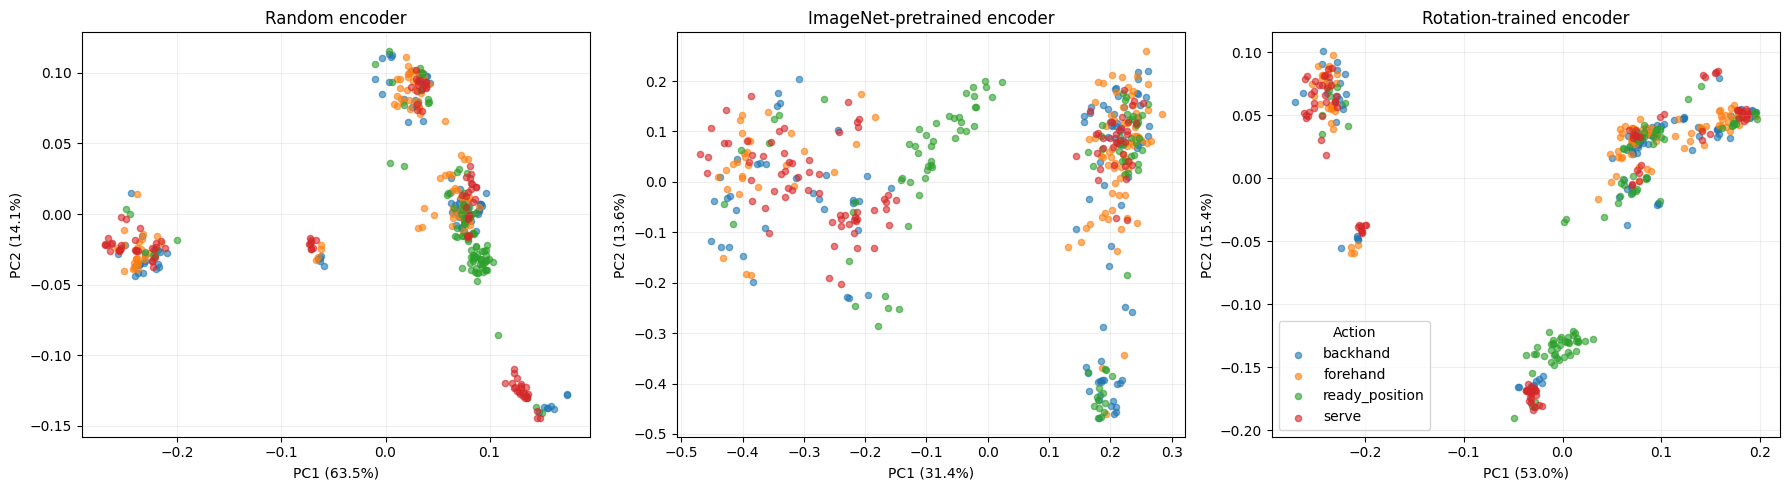

In [28]:
feature_sets = {
    "Random encoder": random_features,
    "ImageNet-pretrained encoder": pretrained_features,
    "Rotation-trained encoder": rotation_features,
}

evaluation_labels = feature_df.iloc[evaluation_indices]["action"].to_numpy()
classes = sorted(feature_df["action"].unique())

cmap = plt.get_cmap("tab10")
class_colors = {action: cmap(i % 10) for i, action in enumerate(classes)}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, features) in zip(axes, feature_sets.items()):
    assert len(features) == len(feature_df)

    evaluation_features = normalize(features[evaluation_indices])
    pca = PCA(n_components=2, svd_solver="full")
    coordinates = pca.fit_transform(evaluation_features)
    variance = 100 * pca.explained_variance_ratio_

    for action in classes:
        mask = evaluation_labels == action
        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            color=class_colors[action],
            label=action,
            s=20,
            alpha=0.6,
        )

    ax.set(
        title=name,
        xlabel=f"PC1 ({variance[0]:.1f}%)",
        ylabel=f"PC2 ({variance[1]:.1f}%)",
    )
    ax.grid(alpha=0.2)

axes[-1].legend(title="Action")
plt.tight_layout()
plt.show()

**Rotation-feature distributions**

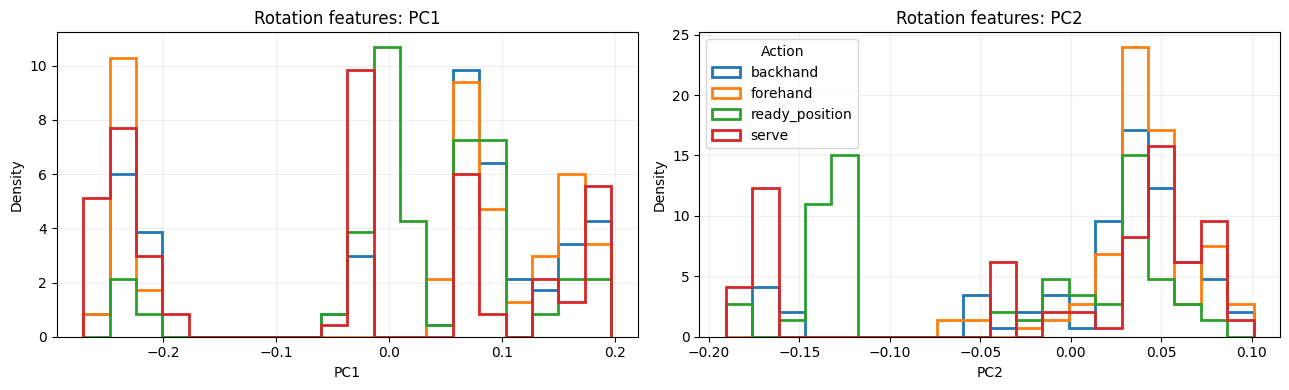

In [29]:
evaluation_rotation_features = normalize(
    rotation_features[evaluation_indices]
)

rotation_pca = PCA(n_components=2, svd_solver="full")
rotation_coordinates = rotation_pca.fit_transform(
    evaluation_rotation_features
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for component, ax in enumerate(axes):
    bins = np.histogram_bin_edges(
        rotation_coordinates[:, component], bins=20
    )

    for action in classes:
        mask = evaluation_labels == action
        ax.hist(
            rotation_coordinates[mask, component],
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=class_colors[action],
            label=action,
        )

    ax.set(
        title=f"Rotation features: PC{component + 1}",
        xlabel=f"PC{component + 1}",
        ylabel="Density",
    )
    ax.grid(alpha=0.2)

axes[-1].legend(title="Action")
plt.tight_layout()
plt.show()

**Compare neighbours using identical queries**

Neighbours are retrieved within the reserved set, excluding the query itself.

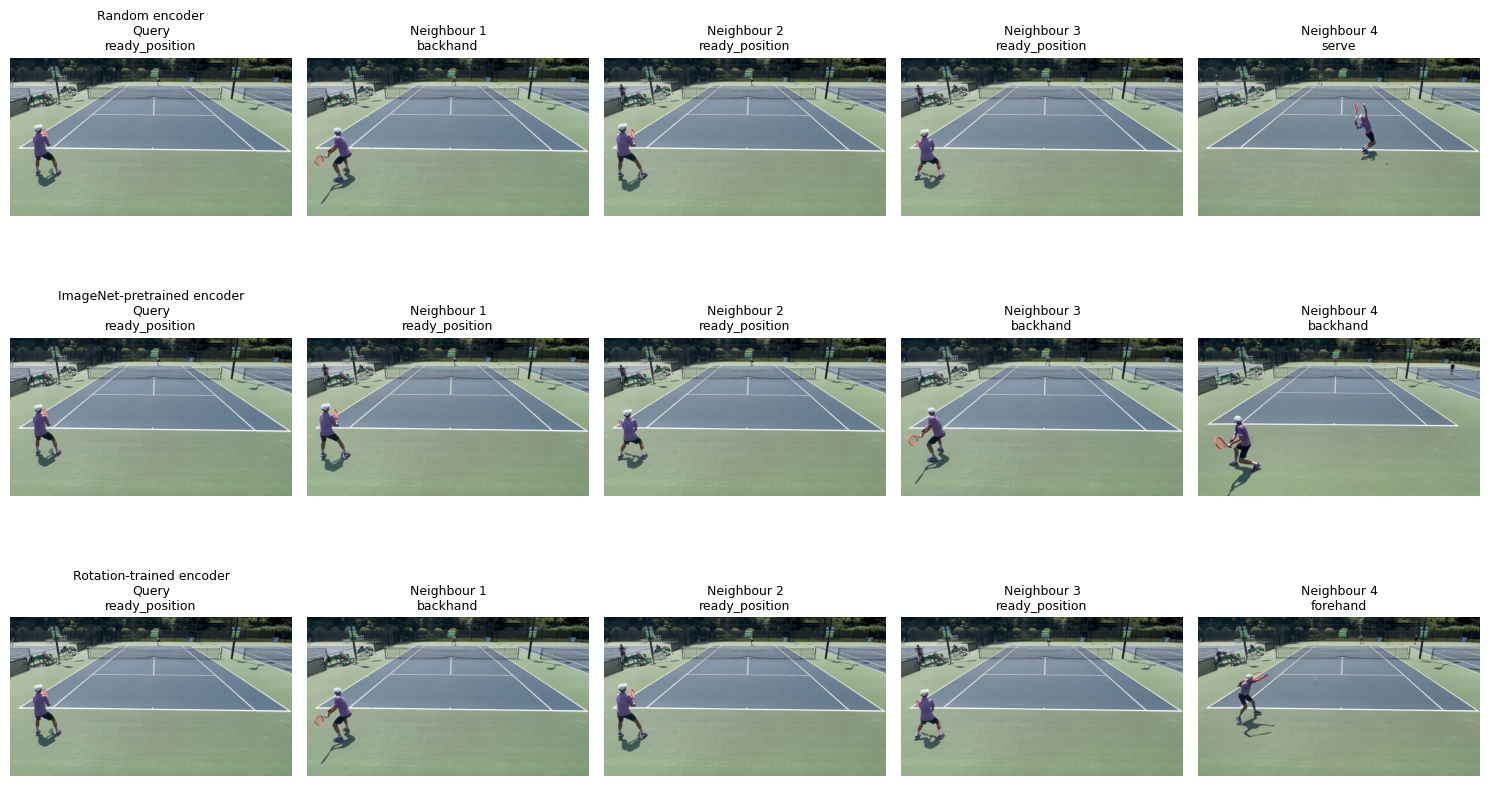

In [30]:
evaluation_frame = feature_df.iloc[evaluation_indices].reset_index(drop=True)

normalized_sets = {
    name: normalize(features[evaluation_indices])
    for name, features in feature_sets.items()
}

def compare_neighbours(query_index, k=4):
    k = min(k, len(evaluation_frame) - 1)

    fig, axes = plt.subplots(
        len(normalized_sets),
        k + 1,
        figsize=(3 * (k + 1), 3 * len(normalized_sets)),
        squeeze=False,
    )

    for row, (name, features) in enumerate(normalized_sets.items()):
        similarities = features @ features[query_index]
        similarities[query_index] = -np.inf
        neighbours = np.argsort(-similarities)[:k]
        indices = [query_index] + neighbours.tolist()

        for column, index in enumerate(indices):
            sample = evaluation_frame.iloc[index]
            ax = axes[row, column]

            with Image.open(sample["path"]) as image:
                ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))

            heading = (
                f"{name}\nQuery"
                if column == 0
                else f"Neighbour {column}"
            )
            ax.set_title(f"{heading}\n{sample['action']}", fontsize=9)
            ax.axis("off")

    plt.tight_layout()
    plt.show()


query_index = evaluation_frame.sample(
    n=1, random_state=SEED
).index[0]

compare_neighbours(query_index)

## Questions

1. Did the model learn to predict rotations on validation images?
2. Is there evidence of overfitting?
3. Compared with random features, what changed in the action distributions?
4. Which encoder retrieves the most relevant neighbours for the same query?
5. Could rotation prediction be relying on court lines or backgrounds?
6. Does high rotation accuracy establish better action classification?
7. What additional experiment is needed to evaluate action information?

Support your answers with examples. An absence of improvement is a valid
result: the pretext task may not encourage the information our application
requires.